# Part 4 – Cancellation model

**Question.** How does the chance that a member cancels depend on the price they are charged? This model gives the tool its cancellation curve, $c(p)$, and answers whether the member discount pays.

**Findings** (details and checks below):

* **Each \$1 higher price this season raises the log-odds of cancelling by 0.30 before the cut and 0.24 after.** Prices are randomized every season, so this is causal. On the probability scale, that is about 3–6 pp per dollar before the cut and 1–3 pp after.
* **Cancellation responds to this season's price, not last season's.** Last season's price adds +0.016 log-odds per dollar, against 0.30 for this season's.
* **Two changes to the starting model.** Tenure enters as one dummy per level, because the linear term misfits by up to 3 pp. The price slope is allowed to differ after the cut: it is stable at 0.28–0.32 in every pre-cut season and drops to 0.22–0.25 after.
* **The member discount paid before the cut but doesn't after it.** Over four seasons, a member paying \$10–\$11 brought in about \$30, against \$22 at the full \$15. After the cut, the full \$12 (\$32.38) and \$11 (\$32.15) bring in about the same, and deeper member discounts bring in less.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

import utils as u

u.apply_style()
CUT = u.CUT_T                                        # spring 2019
FE = 'C(region_name) + C(t)'
BLUE, ORANGE = '#2a78d6', '#eb6834'


def fit_logit(formula, data):
    # Logit with standard errors clustered by customer (a customer appears in several seasons)
    return smf.logit(formula, data=data).fit(disp=0, cov_type='cluster', cov_kwds={'groups': data['customer_id']})


panel = u.load_panel('data/customer_panel.csv', extra_cols=('customer_id',))

## 1. Sample

* **Unit.** One row per customer and season, for customers in the five cut regions who **were members last season**. `cancel` = 1 if they are not a member this season.
* **`price`** is this season's price. Every member gets a discount of \$1–\$5 off, re-randomized each season, and the price is recorded for members who cancel too (as the lowest price available to them). So this season's price is randomized for everyone at risk.
* **`price_lag`** is the price they paid last season. **`tenure_lag`** is how many consecutive seasons they had been a member, up to last season. It restarts if someone cancels and rejoins.
* **Panem is left out.** Its members always pay \$15, so it has no price variation to learn from.

In [2]:
df = panel.sort_values(['customer_id', 't']).reset_index(drop=True)
df['prev_member'] = df.groupby('customer_id')['sign_up_flag'].shift(1)
df['price_lag'] = df.groupby('customer_id')['membership_price'].shift(1)
# Tenure: consecutive seasons as a member, restarting when someone rejoins
spell = (df['sign_up_flag'].eq(1) & df['prev_member'].fillna(0).eq(0)).groupby(df['customer_id']).cumsum()
df['tenure'] = np.where(df['sign_up_flag'].eq(1), df.groupby(['customer_id', spell]).cumcount() + 1, 0)
df['tenure_lag'] = df.groupby('customer_id')['tenure'].shift(1)

d = df[df['region_name'].ne(u.CONTROL) & df['prev_member'].eq(1)].rename(columns={'membership_price': 'price'})
d['cancel'] = 1 - d['sign_up_flag']
d['post'] = d['t'].ge(CUT).astype(int)
d['tenure_lag'] = d['tenure_lag'].astype(int)
del panel, df

print(f"{len(d):,} member-seasons, {d['customer_id'].nunique():,} customers, cancel rate {d['cancel'].mean():.1%}")
display(d.groupby(['post', 'price'])['cancel'].agg(rows='size', cancel_rate='mean').round(4))

# Randomization check: this season's price should be unrelated to tenure and to last season's price
d.groupby(['post', 'price'])[['tenure_lag', 'price_lag']].mean().round(2)

587,701 member-seasons, 140,600 customers, cancel rate 14.2%


rows  cancel_rate
post price                    
0    10     63746       0.1158
     11     63815       0.1448
     12     63288       0.1822
     13     63321       0.2334
     14     63665       0.2902
1    7      54341       0.0506
     8      53733       0.0626
     9      53937       0.0779
     10     53974       0.0959
     11     53881       0.1214

tenure_lag  price_lag
post price                       
0    10           2.44      12.30
     11           2.45      12.29
     12           2.45      12.30
     13           2.45      12.30
     14           2.44      12.29
1    7            3.66      10.13
     8            3.66      10.14
     9            3.66      10.12
     10           3.66      10.14
     11           3.66      10.14

## 2. The starting model

$$\operatorname{logit} P(\text{cancel}_{it}) = \alpha + \beta_1\,\text{price}_{it} + \beta_2\,\text{price}_{i,t-1} + \gamma\,\text{tenure}_{i,t-1} + \mu_r + \lambda_t$$

* $\beta_1$ is causal: this season's price is randomized among members at risk.
* $\beta_2$ is not purely causal. Whether someone was still a member last season depends partly on last season's price, so members who stayed through a high price tend to be more loyal. $\beta_2$ mixes a carry-over effect with that selection.
* $\mu_r$, $\lambda_t$: region and year-season fixed effects. Standard errors are clustered by customer.

In [3]:
model = fit_logit(f'cancel ~ price + price_lag + tenure_lag + {FE}', d)
terms = ['price', 'price_lag', 'tenure_lag']
ci = model.conf_int()
pd.DataFrame({'estimate': model.params[terms], 'ci_low': ci.loc[terms, 0], 'ci_high': ci.loc[terms, 1],
              'p_value': model.pvalues[terms]}).round(4)

,estimate,ci_low,ci_high,p_value
price,0.2797,0.2742,0.2853,0.0
price_lag,0.0322,0.0276,0.0369,0.0
tenure_lag,-0.1040,-0.1092,-0.0988,0.0


## 3. Checks on the starting model

In [4]:
# a. Timing: which season's price drives cancellation?
current = fit_logit(f'cancel ~ price + tenure_lag + {FE}', d)
lagged = fit_logit(f'cancel ~ price_lag + tenure_lag + {FE}', d)
print(f"Adding last season's price to this season's: LR = {2 * (model.llf - current.llf):,.0f}")
print(f"Adding this season's price to last season's: LR = {2 * (model.llf - lagged.llf):,.0f}")
pd.DataFrame({'log-likelihood': [current.llf, lagged.llf, model.llf],
              'price': [current.params['price'], np.nan, model.params['price']],
              'price_lag': [np.nan, lagged.params['price_lag'], model.params['price_lag']]},
             index=["this season's price only", "last season's price only", 'both']).round(3)

Adding last season's price to this season's: LR = 196
Adding this season's price to last season's: LR = 10,291


,log-likelihood,price,price_lag
this season's price only,-222086.070,0.28,NaN
last season's price only,-227133.353,NaN,0.032
both,-221987.894,0.28,0.032


In [5]:
# b. Is tenure linear? One dummy per tenure level vs a straight line
tenure_dummies = fit_logit(f'cancel ~ price + price_lag + C(tenure_lag) + {FE}', d)
lr = 2 * (tenure_dummies.llf - model.llf)
dof = tenure_dummies.df_model - model.df_model
print(f"Tenure dummies vs straight line: LR = {lr:,.0f} on {dof:.0f} df, p = {stats.chi2.sf(lr, dof):.2g}")
by_tenure = d.assign(linear=model.predict(d), dummies=tenure_dummies.predict(d)).groupby('tenure_lag').agg(
    rows=('cancel', 'size'), actual=('cancel', 'mean'), linear_tenure=('linear', 'mean'), tenure_dummies=('dummies', 'mean'))
by_tenure['gap_linear_pp'] = 100 * (by_tenure['actual'] - by_tenure['linear_tenure'])
del tenure_dummies
by_tenure.round(4)

Tenure dummies vs straight line: LR = 1,821 on 9 df, p = 0


,rows,actual,linear_tenure,tenure_dummies,gap_linear_pp
tenure_lag,,,,,
1,177155,0.2011,0.1840,0.2011,1.7179
2,123112,0.1486,0.1613,0.1486,-1.2701
3,97729,0.1128,0.1296,0.1128,-1.6830
4,66173,0.1179,0.1316,0.1179,-1.3687
5,54445,0.0826,0.0926,0.0826,-1.0024
6,22367,0.1172,0.0875,0.1172,2.9746
7,18802,0.0925,0.0671,0.0925,2.5415
8,12425,0.0773,0.0533,0.0773,2.4017
9,8608,0.0627,0.0498,0.0627,1.2930


In [6]:
# c. Is the price slope stable over time? One price slope per season
seasons = sorted(d['t'].unique())
slope_terms = [f'price_t{k}' for k in seasons]
by_season = d.assign(**{f'price_t{k}': d['price'] * d['t'].eq(k) for k in seasons})
fit_s = fit_logit('cancel ~ ' + ' + '.join(slope_terms) + f' + price_lag + C(tenure_lag) + {FE}', by_season)
slopes = pd.DataFrame({'price slope': fit_s.params[slope_terms].to_numpy(),
                       'cancel rate': d.groupby('t')['cancel'].mean().to_numpy()},
                      index=[u.period_label(k) for k in seasons])
del fit_s, by_season
slopes.round(3).T

,Spr 2017,Sum 2017,Fall 2017,Win 2018,Spr 2018,Sum 2018,Fall 2018,Win 2019,Spr 2019,Sum 2019,Fall 2019
price slope,0.316,0.297,0.300,0.323,0.306,0.295,0.276,0.287,0.252,0.249,0.221
cancel rate,0.287,0.228,0.234,0.224,0.291,0.174,0.147,0.115,0.083,0.092,0.072


**Reading**

* **This season's price drives cancellation.** Dropping it costs far more fit (LR = 10,291) than dropping last season's price (LR = 196). Last season's price adds only 0.032 per dollar against 0.28 for this season's, and part of that is selection.
* **Tenure is not linear.** One dummy per level fits much better (LR = 1,821 on 9 df). The straight line misses by up to 3 pp: cancellation drops steeply over the first few seasons, then flattens.
* **The price slope breaks at the cut.** It is 0.28–0.32 in every pre-cut season and 0.22–0.25 in every post-cut season. So this is a change in level at the cut, not season-to-season noise, and the final model lets the slope differ after the cut.

## 4. Final model

The starting model with two changes: tenure as one dummy per level (8 or more seasons grouped, since few members get that far and the tool needs a level for longer tenures), and a separate price slope after the cut (`price_post` = price × post-cut).

In [7]:
d['price_post'] = d['price'] * d['post']
d['tenure_group'] = d['tenure_lag'].clip(upper=8)
FINAL = f'cancel ~ price + price_post + price_lag + C(tenure_group) + {FE}'
final = fit_logit(FINAL, d)

terms = ['price', 'price_post', 'price_lag']
ci = final.conf_int()
display(pd.DataFrame({'estimate': final.params[terms], 'ci_low': ci.loc[terms, 0], 'ci_high': ci.loc[terms, 1],
                      'p_value': final.pvalues[terms]}).round(4))
print(f"Price slope before the cut {final.params['price']:.3f}, after {final.params['price'] + final.params['price_post']:.3f}")

# Calibration by price, and the effect of $1 more on the probability scale
d['p_hat'] = final.predict(d)
d['pp_per_dollar'] = 100 * (final.predict(d.assign(price=d['price'] + 1, price_post=(d['price'] + 1) * d['post'])) - d['p_hat'])
cal = d.groupby(['post', 'price']).agg(actual=('cancel', 'mean'), predicted=('p_hat', 'mean'),
                                       pp_per_dollar=('pp_per_dollar', 'mean'))
cal['gap_pp'] = 100 * (cal['actual'] - cal['predicted'])
print(f"Largest gap by price: {cal['gap_pp'].abs().max():.2f} pp")
cal.round(4)

,estimate,ci_low,ci_high,p_value
price,0.2982,0.2915,0.3048,0.0
price_post,-0.0573,-0.0694,-0.0452,0.0
price_lag,0.0159,0.0112,0.0205,0.0


Price slope before the cut 0.298, after 0.241
Largest gap by price: 0.37 pp


actual  predicted  pp_per_dollar  gap_pp
post price                                          
0    10     0.1158     0.1134         3.2663  0.2383
     11     0.1448     0.1456         3.9759 -0.0840
     12     0.1822     0.1859         4.7457 -0.3666
     13     0.2334     0.2332         5.4911  0.0273
     14     0.2902     0.2884         6.1648  0.1829
1    7      0.0506     0.0500         1.2680  0.0588
     8      0.0626     0.0627         1.5632 -0.0178
     9      0.0779     0.0781         1.9044 -0.0242
     10     0.0959     0.0972         2.3054 -0.1352
     11     0.1214     0.1203         2.7563  0.1181

## 5. Cancel rate and revenue per member at each member price

What happens if members paid a fixed price every season: this season's and last season's price are both set to that price, everything else as observed. Revenue per member over the next four seasons is

$$p \sum_{s=1}^{4} \big(1 - c(p)\big)^s,$$

which holds the cancel rate at $c(p)$ and ignores members growing more loyal with tenure. **No member pays full price in the data** (\$15 before the cut, \$12 after), so those rows extend the model one dollar beyond the observed prices.

In [8]:
rows = []
for flag, base in [(0, 15), (1, 12)]:
    members = d[d['post'].eq(flag)]
    for p in range(base - 5, base + 1):
        c = final.predict(members.assign(price=p, price_lag=p, price_post=p * flag)).mean()
        rows.append({'period': 'post-cut' if flag else 'pre-cut', 'member price': p, 'discount': base - p,
                     'cancel rate': c, 'revenue per member, 4 seasons': p * sum((1 - c) ** s for s in range(1, 5)),
                     'in the data': p < base})
member_value = pd.DataFrame(rows).set_index(['period', 'member price'])
member_value.round(3)

discount  cancel rate  revenue per member, 4 seasons  \
period   member price                                                         
pre-cut  10                   5        0.110                         30.171   
         11                   4        0.143                         30.334   
         12                   3        0.185                         29.544   
         13                   2        0.235                         27.825   
         14                   1        0.293                         25.315   
         15                   0        0.359                         22.260   
post-cut 7                    5        0.048                         24.826   
         8                    4        0.061                         27.440   
         9                    3        0.077                         29.598   
         10                   2        0.097                         31.201   
         11                   1        0.122                         32.152   
         12                   0        0.151                         32.375   

                       in the data  
period   member price               
pre-cut  10                   True  
         11                   True  
         12                   True  
         13                   True  
         14                   True  
         15                  False  
post-cut 7                    True  
         8                    True  
         9                    True  
         10                   True  
         11                   True  
         12                  False

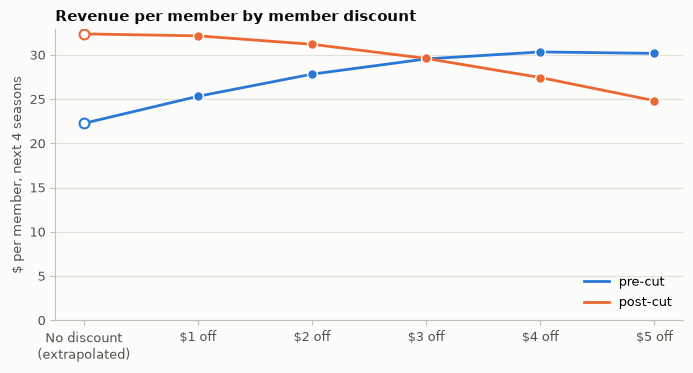

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for (name, g), color in zip(member_value.groupby(level='period', sort=False), [BLUE, ORANGE]):
    g = g.droplevel('period')
    ax.plot(g['discount'], g['revenue per member, 4 seasons'], color=color, lw=2, label=name)
    seen, extra = g[g['in the data']], g[~g['in the data']]
    ax.scatter(seen['discount'], seen['revenue per member, 4 seasons'], s=50, color=color, edgecolor='white', zorder=3)
    ax.scatter(extra['discount'], extra['revenue per member, 4 seasons'], s=50, facecolor='white', edgecolor=color,
               linewidth=1.5, zorder=3)
ax.set_xticks(range(6), ['No discount\n(extrapolated)'] + [f'${k} off' for k in range(1, 6)])
ax.set_ylim(0, None)
ax.set_ylabel('$ per member, next 4 seasons')
ax.set_title('Revenue per member by member discount', loc='left')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout()
plt.show()

**Reading**

* **Before the cut, the member discount pays.** Members charged \$10–\$11 bring in about \$30 over four seasons, against \$22 at the full \$15, where about 36% would cancel each season.
* **After the cut, it doesn't.** The full \$12 (\$32.38) and \$11 (\$32.15) are about the same, and deeper discounts bring in less (\$24.83 at \$7). With the lower base price, cancellation is already low (15% at \$12), so further discounts mostly give money away. Today's \$1–\$5 member prices average about \$29.0 per member, so charging members the full \$12 would bring in roughly \$3.3 more each over four seasons. The tool should confirm this, since it is the largest pricing lever in the data.
* **The full-price rows are extrapolations,** one dollar beyond the observed prices. Panem's members, who always pay \$15, cancel at 33.7% before the cut: a rough check only, since they are a different population.

**Caveats**

* Revenue, not margin. Holding the cancel rate fixed ignores members growing more loyal over time.
* The model is fit on the five cut regions. Applying it to Panem assumes Panem's members respond to price the same way.
* `price_lag` mixes a carry-over effect with selection. In the tool, a fixed price sets both prices equal, so this matters little.

In [10]:
out = Path('outputs')
out.mkdir(exist_ok=True)
final.params.rename('coefficient').to_csv(out / 'cancel_model_params.csv')
member_value.to_csv(out / 'member_value_by_price.csv')